# EDA: MovieLens 1M

Пять вопросов к данным перед построением рекомендательной системы. У каждого вопроса есть график и вывод одной строкой.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from recsys.data.movielens import load_movies, load_ratings

raw_dir = Path("../data/raw/ml-1m")
ratings = load_ratings(raw_dir)
movies = load_movies(raw_dir)
print(
    f"ratings: {len(ratings):,}, users: {ratings.user_id.nunique():,}, "
    f"movies rated: {ratings.movie_id.nunique():,} of {len(movies):,}"
)

ratings: 1,000,209, users: 6,040, movies rated: 3,706 of 3,883


## 1. Распределение оценок 1-5

Какие оценки ставят чаще всего? Это влияет на выбор между явной (rating) и неявной (факт оценки) обратной связью.

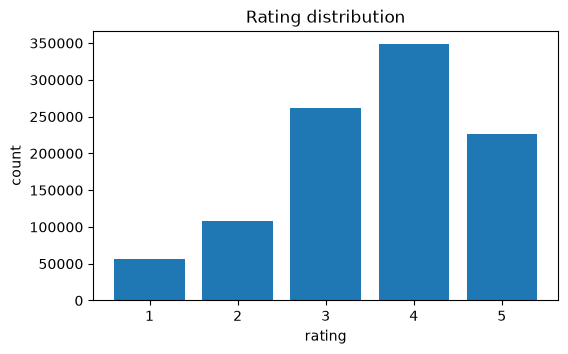

Вывод: чаще всего ставят 4, оценки 4-5 составляют 58% - выборка смещена в позитив.


In [2]:
counts = ratings["rating"].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.bar(counts.index, counts.values)
ax.set_xlabel("rating")
ax.set_ylabel("count")
ax.set_title("Rating distribution")
plt.show()
share_pos = (ratings["rating"] >= 4).mean()
print(
    f"Вывод: чаще всего ставят {counts.idxmax()}, оценки 4-5 составляют {share_pos:.0%} "
    f"- выборка смещена в позитив."
)

## 2. Число оценок на пользователя

Лог-шкала: видим ли длинный хвост?

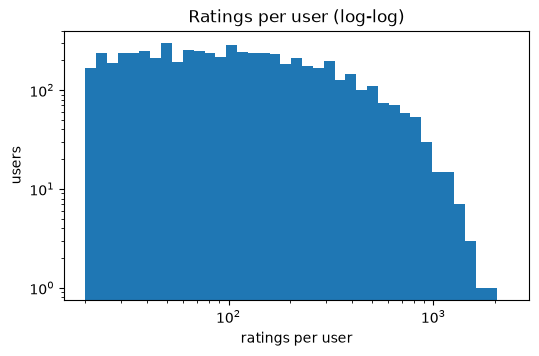

Вывод: минимум 20, медиана 96, максимум 2314 оценок на пользователя - длинный хвост активных пользователей.


In [3]:
per_user = ratings.groupby("user_id").size()
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.hist(per_user, bins=np.logspace(np.log10(per_user.min()), np.log10(per_user.max()), 40))
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("ratings per user")
ax.set_ylabel("users")
ax.set_title("Ratings per user (log-log)")
plt.show()
print(
    f"Вывод: минимум {per_user.min()}, медиана {per_user.median():.0f}, максимум "
    f"{per_user.max()} оценок на пользователя - длинный хвост активных пользователей."
)

## 3. Число оценок на фильм

Сколько фильмов почти никто не оценил (проблема холодного хвоста)?

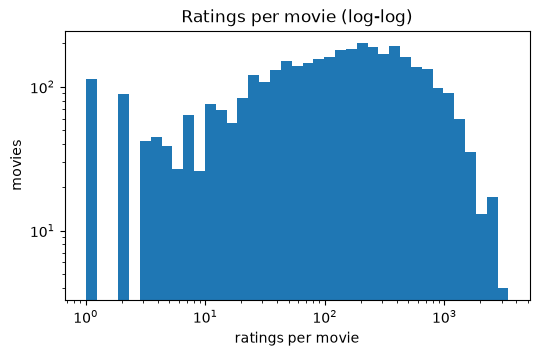

Вывод: 446 из 3706 фильмов (12%) имеют меньше 10 оценок, а самый популярный - 3428.


In [4]:
per_movie = ratings.groupby("movie_id").size()
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.hist(per_movie, bins=np.logspace(0, np.log10(per_movie.max()), 40))
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("ratings per movie")
ax.set_ylabel("movies")
ax.set_title("Ratings per movie (log-log)")
plt.show()
rare = (per_movie < 10).sum()
print(
    f"Вывод: {rare} из {len(per_movie)} фильмов ({rare / len(per_movie):.0%}) "
    f"имеют меньше 10 оценок, "
    f"а самый популярный - {per_movie.max()}."
)

## 4. Период данных

Когда поставлены оценки? Это важно для временного разбиения.

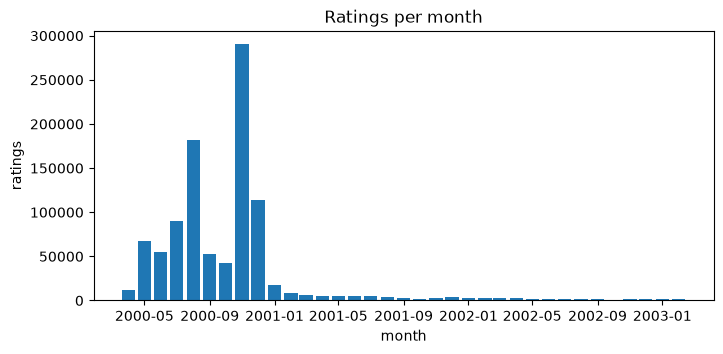

Вывод: данные с 2000-04-25 по 2003-02-28, пик активности - 2000-11 (290,793 оценок, 29% всех).


In [5]:
ts = pd.to_datetime(ratings["timestamp"], unit="s")
by_month = ts.dt.to_period("M").value_counts().sort_index()
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.bar(by_month.index.to_timestamp(), by_month.values, width=25)
ax.set_xlabel("month")
ax.set_ylabel("ratings")
ax.set_title("Ratings per month")
plt.show()
top_month = by_month.idxmax()
print(
    f"Вывод: данные с {ts.min():%Y-%m-%d} по {ts.max():%Y-%m-%d}, "
    f"пик активности - {top_month} ({by_month.max():,} оценок, "
    f"{by_month.max() / len(ratings):.0%} всех)."
)

## 5. Одинаковый timestamp у оценок одного пользователя

Почему в split нужен tie-break: если много оценок пользователя имеют одинаковое время, порядок "по времени" неоднозначен.

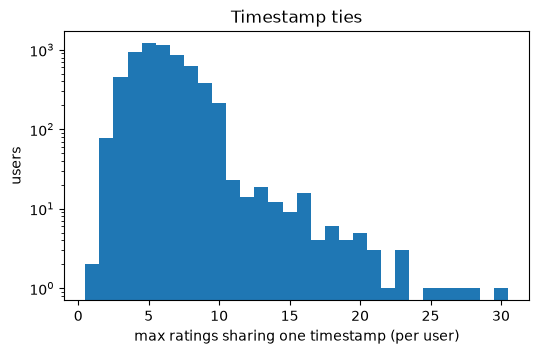

Вывод: у 100% пользователей есть оценки с общим timestamp (до 30 штук), всего 77% оценок попадают в такие группы - без tie-break граница train/test была бы недетерминированной.


In [6]:
same_ts = ratings.groupby(["user_id", "timestamp"]).size().rename("n").reset_index()
max_tie = same_ts.groupby("user_id")["n"].max()
in_ties = ratings.merge(same_ts[same_ts["n"] > 1][["user_id", "timestamp"]]).shape[0]
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.hist(max_tie, bins=np.arange(1, max_tie.max() + 2) - 0.5)
ax.set_yscale("log")
ax.set_xlabel("max ratings sharing one timestamp (per user)")
ax.set_ylabel("users")
ax.set_title("Timestamp ties")
plt.show()
print(
    f"Вывод: у {(max_tie > 1).mean():.0%} пользователей есть оценки с общим timestamp "
    f"(до {max_tie.max()} штук), всего {in_ties / len(ratings):.0%} "
    f"оценок попадают в такие группы - "
    f"без tie-break граница train/test была бы недетерминированной."
)